TAHAP PENGOLAHAN CITRA

In [1]:
# Import Library

import cv2
import os
import numpy as np
import matplotlib.pyplot as plt

from skimage.feature import graycomatrix, graycoprops

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, precision_score, recall_score, f1_score

import joblib

Data ke-1
Label : baik
Nama File : IMG_20260402_221214.jpg


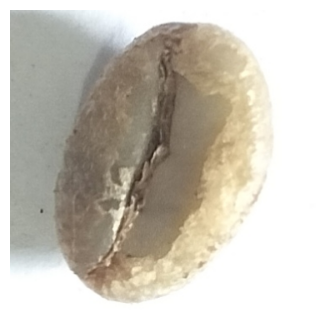

Data ke-2
Label : baik
Nama File : IMG_20260402_221414.jpg


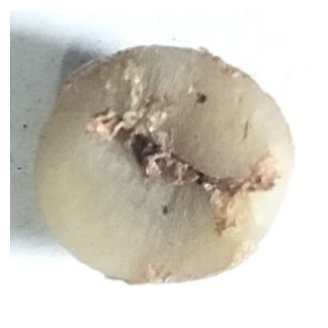

Data ke-3
Label : baik
Nama File : IMG_20260402_221450.jpg


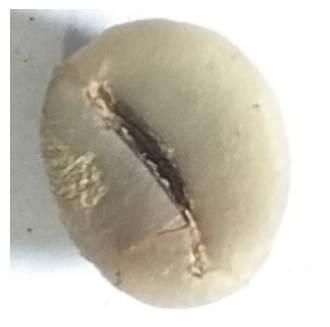

Data ke-4
Label : baik
Nama File : IMG_20260402_221509.jpg


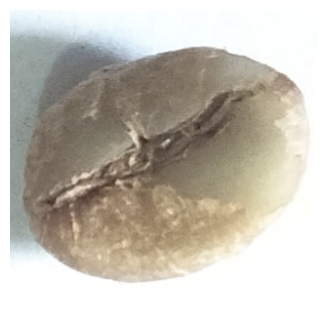

Data ke-5
Label : baik
Nama File : IMG_20260402_221834.jpg


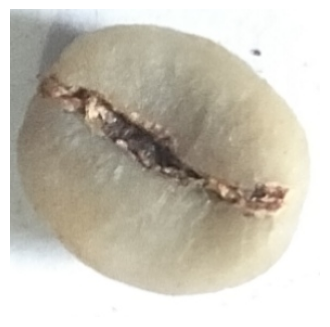

Data ke-6
Label : baik
Nama File : IMG_20260402_221858.jpg


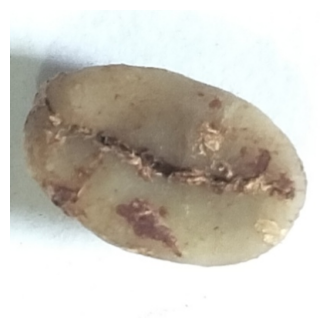

Data ke-7
Label : baik
Nama File : IMG_20260402_221917.jpg


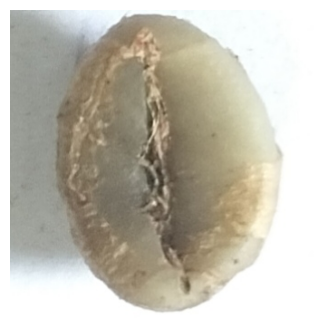

Data ke-8
Label : baik
Nama File : IMG_20260402_221936.jpg


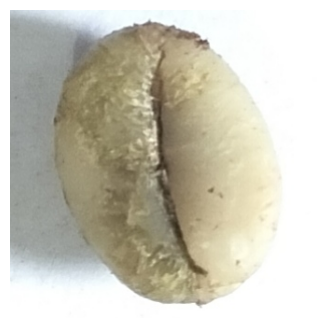

Data ke-9
Label : baik
Nama File : IMG_20260402_222008.jpg


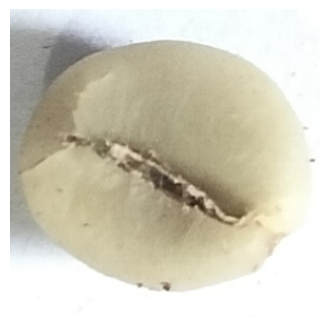

Data ke-10
Label : baik
Nama File : IMG_20260402_222035.jpg


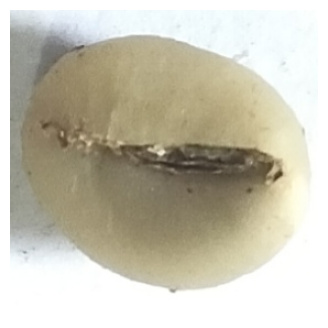

In [2]:
images = []
labels = []
filenames = []

jumlah_data = 0

for label in ['baik', 'buruk']:

    path = os.path.join("../dataset", label)
    files = sorted(os.listdir(path))

    for file in files:

        img_path = os.path.join(path, file)
        img = cv2.imread(img_path)

        if img is None:
            continue

        images.append(img)
        labels.append(label)
        filenames.append(file)

        jumlah_data += 1

        print(f"Data ke-{jumlah_data}")
        print("Label :", label)
        print("Nama File :", file)

        plt.figure(figsize=(4,4))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.axis("off")
        plt.show()

        if jumlah_data == 10:
            break

    if jumlah_data == 10:
        break

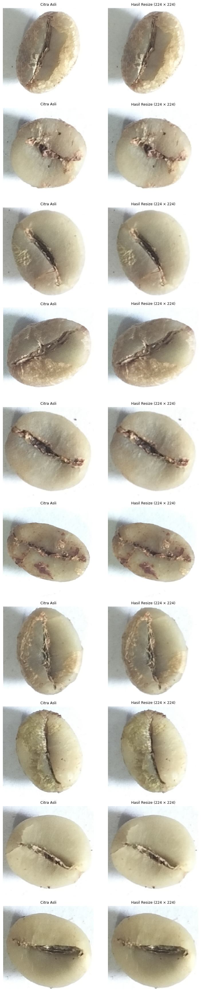

In [3]:
fig, axes = plt.subplots(10, 2, figsize=(8, 35))

for i in range(10):

    # Citra asli
    img_asli = cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB)

    # Resize
    img_resize = cv2.resize(images[i], (224,224))
    img_resize = cv2.cvtColor(img_resize, cv2.COLOR_BGR2RGB)

    # Kolom kiri = Citra Asli
    axes[i,0].imshow(img_asli)
    axes[i,0].set_title("Citra Asli", fontsize=9)
    axes[i,0].axis("off")

    # Kolom kanan = Hasil Resize
    axes[i,1].imshow(img_resize)
    axes[i,1].set_title("Hasil Resize (224 × 224)", fontsize=9)
    axes[i,1].axis("off")

plt.tight_layout()
plt.show()

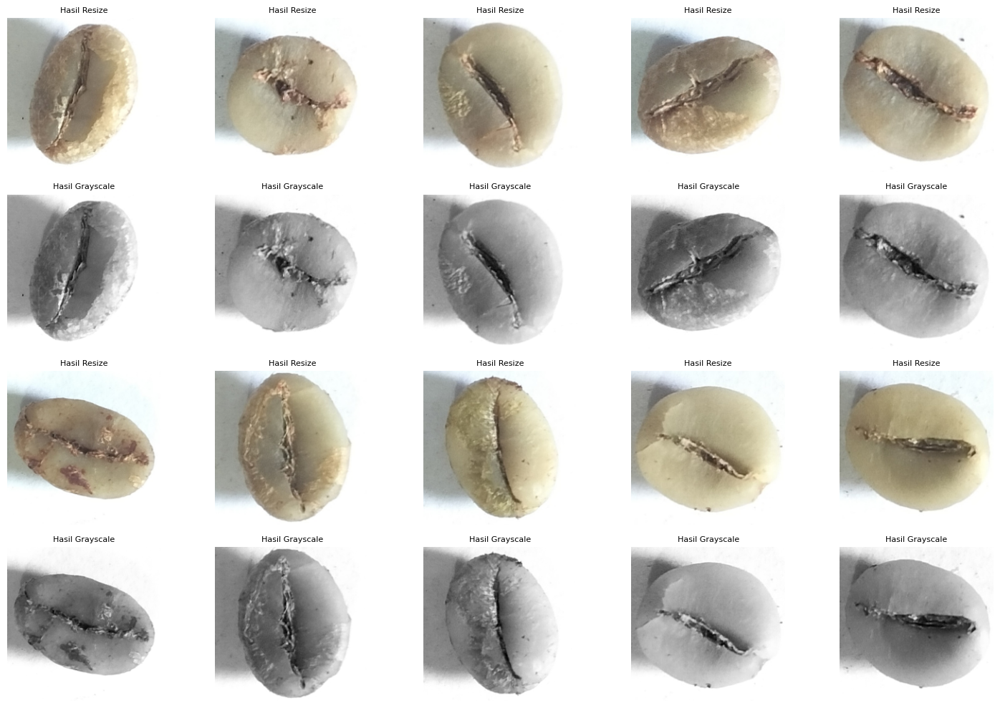

In [4]:
fig, axes = plt.subplots(4, 5, figsize=(15, 10))

for i in range(10):

    # Resize
    img_resize = cv2.resize(images[i], (224,224))
    img_resize_rgb = cv2.cvtColor(img_resize, cv2.COLOR_BGR2RGB)

    # Grayscale
    gray = cv2.cvtColor(img_resize, cv2.COLOR_BGR2GRAY)

    r = (i // 5) * 2
    c = i % 5

    # Baris atas = Hasil Resize
    axes[r, c].imshow(img_resize_rgb)
    axes[r, c].set_title("Hasil Resize", fontsize=8)
    axes[r, c].axis("off")

    # Baris bawah = Hasil Grayscale
    axes[r+1, c].imshow(gray, cmap="gray")
    axes[r+1, c].set_title("Hasil Grayscale", fontsize=8)
    axes[r+1, c].axis("off")

plt.tight_layout()
plt.show()

===== Data 1 =====
Nama File : IMG_20260402_221214.jpg
Mean Red   : 195.68
Mean Green : 189.64
Mean Blue  : 177.49
----------------------------------------


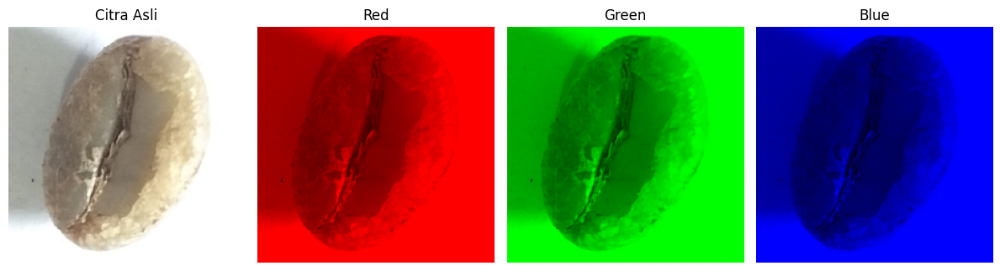

===== Data 2 =====
Nama File : IMG_20260402_221414.jpg
Mean Red   : 205.28
Mean Green : 200.18
Mean Blue  : 188.18
----------------------------------------


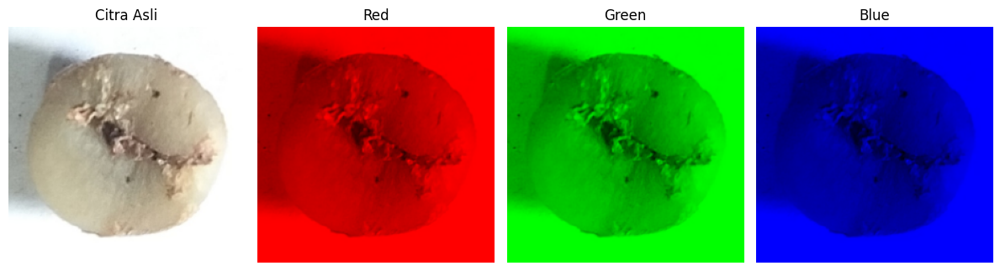

===== Data 3 =====
Nama File : IMG_20260402_221450.jpg
Mean Red   : 193.10
Mean Green : 187.76
Mean Blue  : 173.79
----------------------------------------


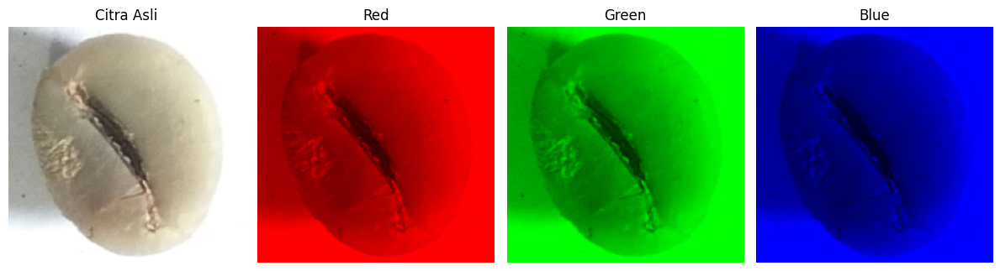

===== Data 4 =====
Nama File : IMG_20260402_221509.jpg
Mean Red   : 190.21
Mean Green : 184.47
Mean Blue  : 173.20
----------------------------------------


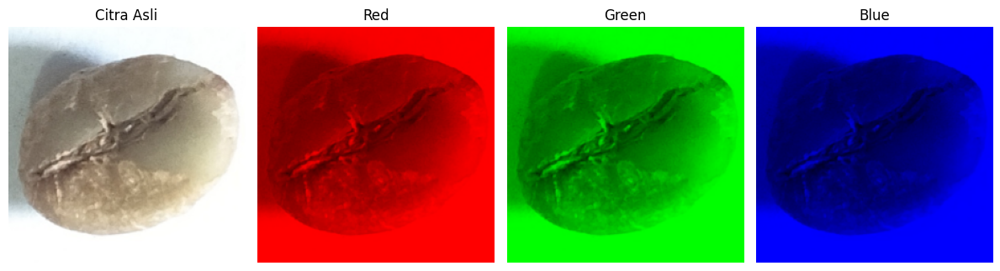

===== Data 5 =====
Nama File : IMG_20260402_221834.jpg
Mean Red   : 193.77
Mean Green : 188.04
Mean Blue  : 174.16
----------------------------------------


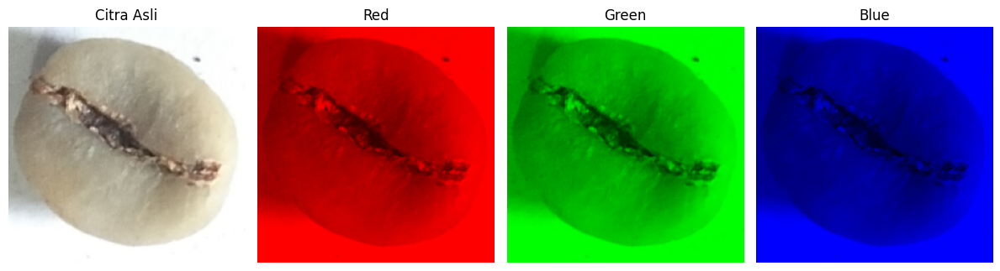

===== Data 6 =====
Nama File : IMG_20260402_221858.jpg
Mean Red   : 199.75
Mean Green : 194.85
Mean Blue  : 184.71
----------------------------------------


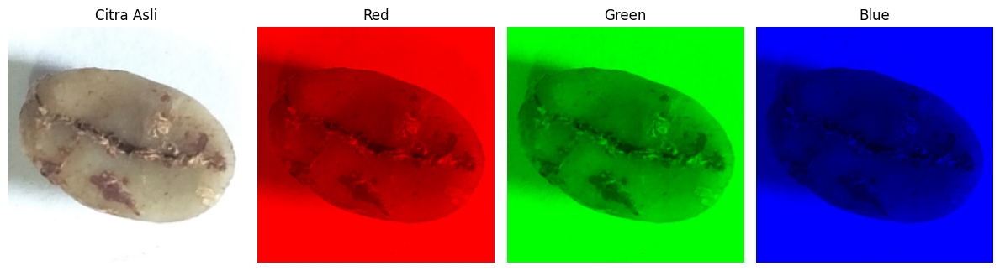

===== Data 7 =====
Nama File : IMG_20260402_221917.jpg
Mean Red   : 187.33
Mean Green : 182.74
Mean Blue  : 168.89
----------------------------------------


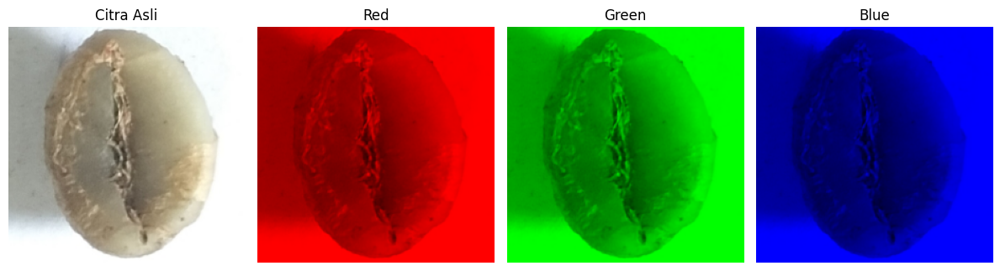

===== Data 8 =====
Nama File : IMG_20260402_221936.jpg
Mean Red   : 195.65
Mean Green : 192.37
Mean Blue  : 176.61
----------------------------------------


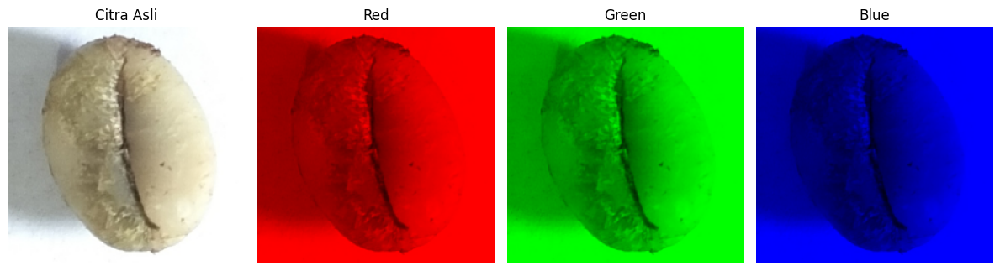

===== Data 9 =====
Nama File : IMG_20260402_222008.jpg
Mean Red   : 206.67
Mean Green : 202.45
Mean Blue  : 184.29
----------------------------------------


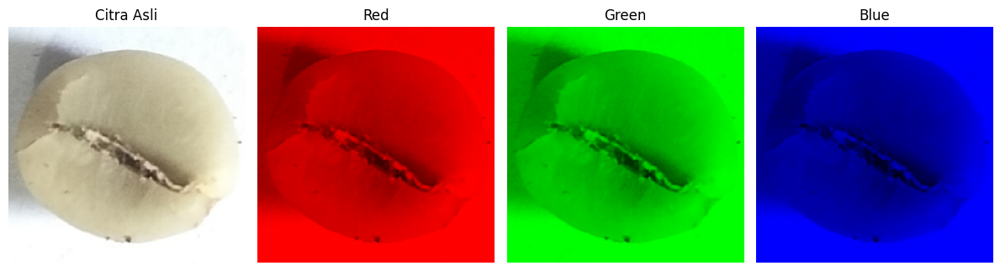

===== Data 10 =====
Nama File : IMG_20260402_222035.jpg
Mean Red   : 191.53
Mean Green : 187.04
Mean Blue  : 168.55
----------------------------------------


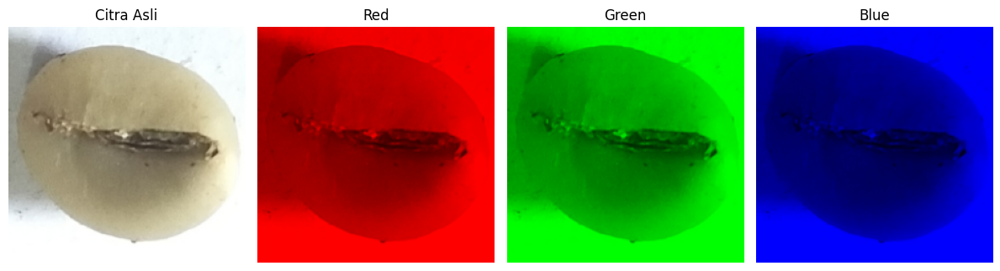

In [5]:
# EKSTRAKSI FITUR WARNA RGB (10 DATA PERTAMA)

for i in range(10):

    img_resize = cv2.resize(images[i], (224, 224))

    mean_r = np.mean(img_resize[:, :, 2])
    mean_g = np.mean(img_resize[:, :, 1])
    mean_b = np.mean(img_resize[:, :, 0])

    print(f"===== Data {i+1} =====")
    print(f"Nama File : {filenames[i]}")
    print(f"Mean Red   : {mean_r:.2f}")
    print(f"Mean Green : {mean_g:.2f}")
    print(f"Mean Blue  : {mean_b:.2f}")
    print("-"*40)

    rgb = cv2.cvtColor(img_resize, cv2.COLOR_BGR2RGB)

    R = rgb.copy()
    R[:, :, 1] = 0
    R[:, :, 2] = 0

    G = rgb.copy()
    G[:, :, 0] = 0
    G[:, :, 2] = 0

    B = rgb.copy()
    B[:, :, 0] = 0
    B[:, :, 1] = 0

    plt.figure(figsize=(12,4))

    plt.subplot(1,4,1)
    plt.imshow(rgb)
    plt.title("Citra Asli")
    plt.axis("off")

    plt.subplot(1,4,2)
    plt.imshow(R)
    plt.title("Red")
    plt.axis("off")

    plt.subplot(1,4,3)
    plt.imshow(G)
    plt.title("Green")
    plt.axis("off")

    plt.subplot(1,4,4)
    plt.imshow(B)
    plt.title("Blue")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

===== Data 1 =====
Nama File      : IMG_20260402_221214.jpg
Contrast       : 48.9948
Energy         : 0.2930
Homogeneity    : 0.5041
Dissimilarity  : 3.1613
Correlation    : 0.9924
ASM            : 0.0858
---------------------------------------------


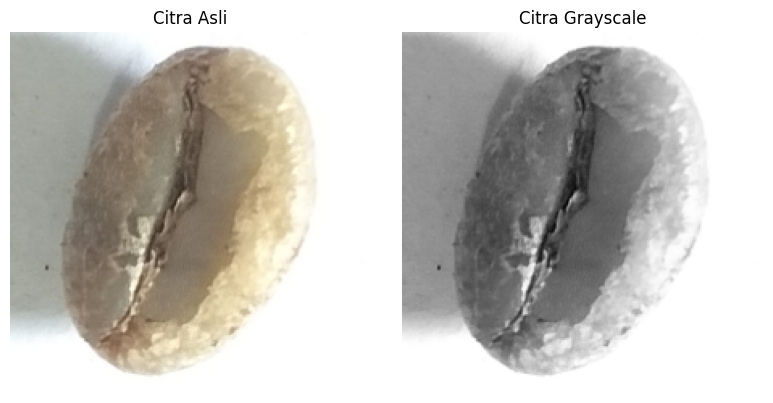

===== Data 2 =====
Nama File      : IMG_20260402_221414.jpg
Contrast       : 34.3832
Energy         : 0.2640
Homogeneity    : 0.5163
Dissimilarity  : 2.8115
Correlation    : 0.9927
ASM            : 0.0697
---------------------------------------------


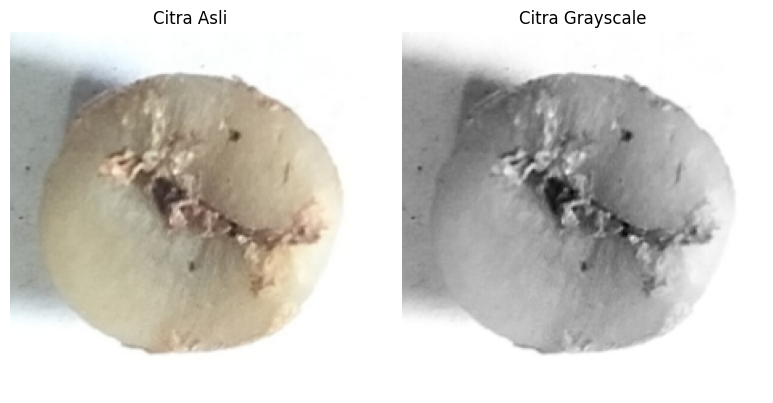

===== Data 3 =====
Nama File      : IMG_20260402_221450.jpg
Contrast       : 25.5048
Energy         : 0.2206
Homogeneity    : 0.4929
Dissimilarity  : 2.4911
Correlation    : 0.9953
ASM            : 0.0487
---------------------------------------------


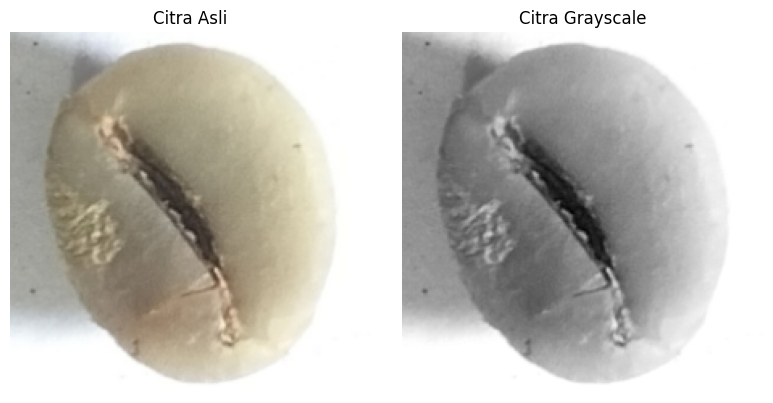

===== Data 4 =====
Nama File      : IMG_20260402_221509.jpg
Contrast       : 32.3019
Energy         : 0.2002
Homogeneity    : 0.4606
Dissimilarity  : 3.0312
Correlation    : 0.9953
ASM            : 0.0401
---------------------------------------------


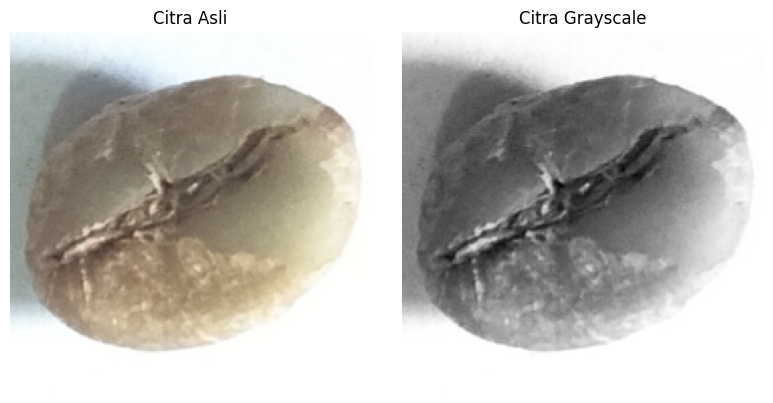

===== Data 5 =====
Nama File      : IMG_20260402_221834.jpg
Contrast       : 25.9704
Energy         : 0.1585
Homogeneity    : 0.4648
Dissimilarity  : 2.6397
Correlation    : 0.9949
ASM            : 0.0251
---------------------------------------------


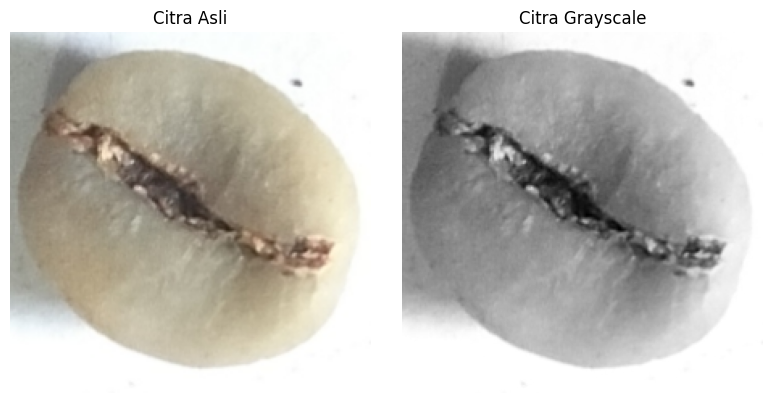

===== Data 6 =====
Nama File      : IMG_20260402_221858.jpg
Contrast       : 28.3983
Energy         : 0.2427
Homogeneity    : 0.5388
Dissimilarity  : 2.5135
Correlation    : 0.9960
ASM            : 0.0589
---------------------------------------------


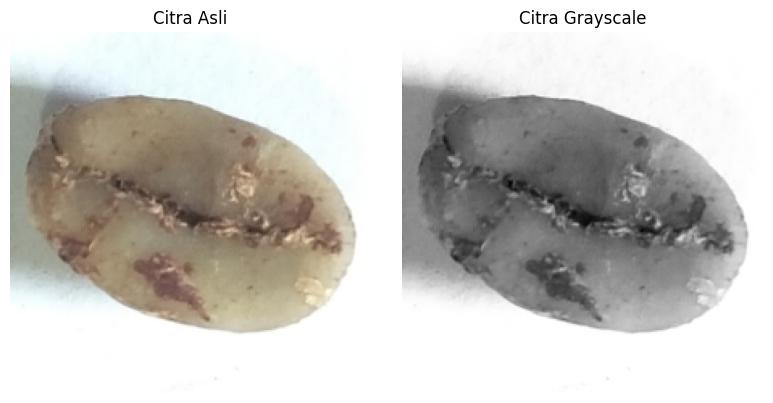

===== Data 7 =====
Nama File      : IMG_20260402_221917.jpg
Contrast       : 41.6120
Energy         : 0.1699
Homogeneity    : 0.4602
Dissimilarity  : 3.1234
Correlation    : 0.9927
ASM            : 0.0289
---------------------------------------------


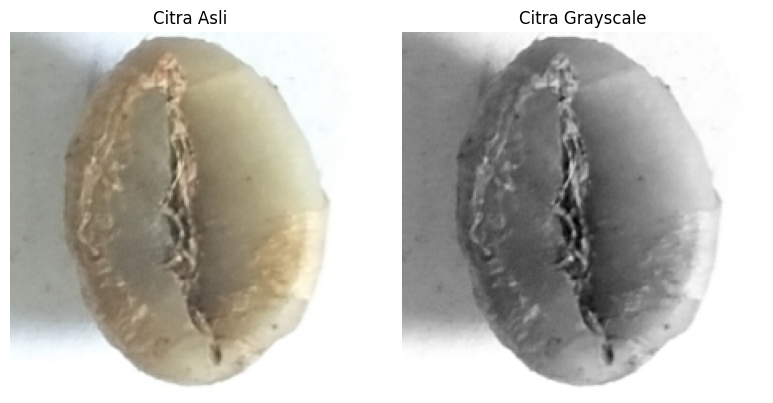

===== Data 8 =====
Nama File      : IMG_20260402_221936.jpg
Contrast       : 34.6421
Energy         : 0.1881
Homogeneity    : 0.4750
Dissimilarity  : 2.8905
Correlation    : 0.9937
ASM            : 0.0354
---------------------------------------------


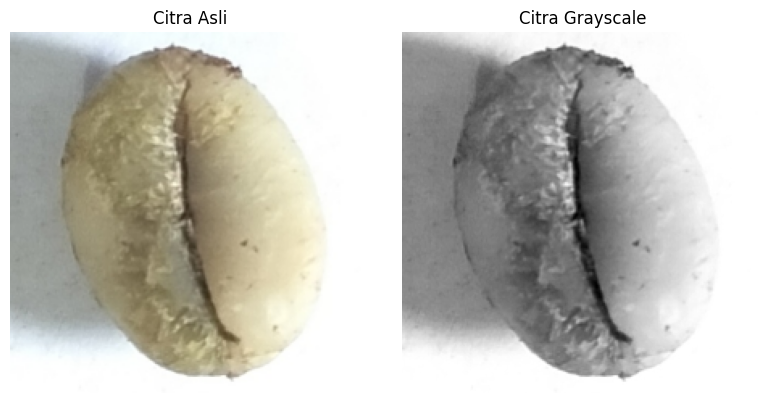

===== Data 9 =====
Nama File      : IMG_20260402_222008.jpg
Contrast       : 19.8341
Energy         : 0.1405
Homogeneity    : 0.5050
Dissimilarity  : 2.1193
Correlation    : 0.9948
ASM            : 0.0197
---------------------------------------------


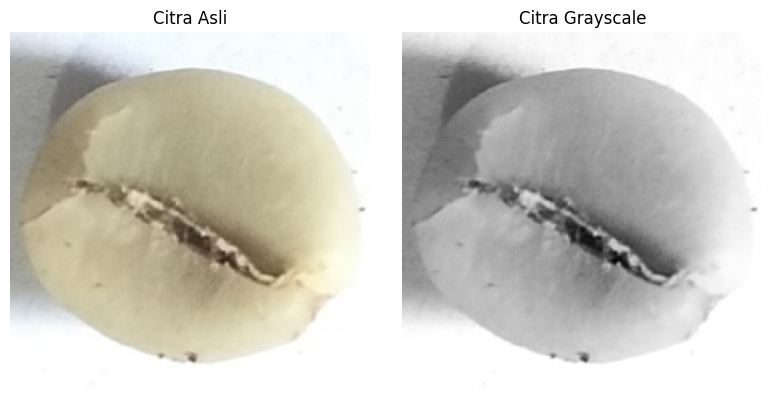

===== Data 10 =====
Nama File      : IMG_20260402_222035.jpg
Contrast       : 15.2606
Energy         : 0.1389
Homogeneity    : 0.4950
Dissimilarity  : 2.0325
Correlation    : 0.9974
ASM            : 0.0193
---------------------------------------------


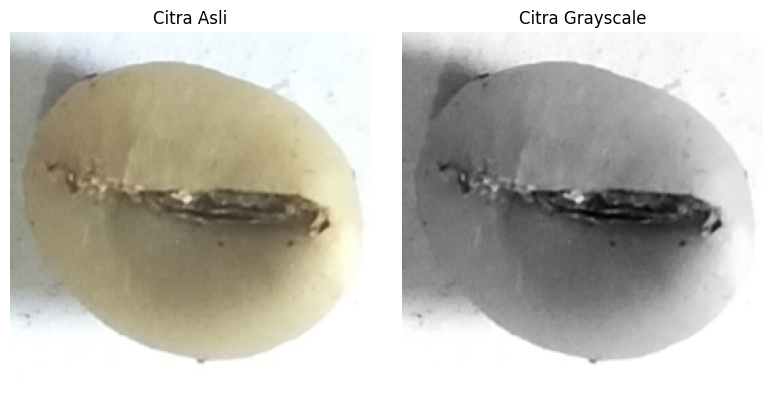

In [6]:
# EKSTRAKSI FITUR GLCM (10 DATA PERTAMA)

for i in range(10):

    # Resize
    img_resize = cv2.resize(images[i], (224,224))

    # RGB untuk ditampilkan
    rgb = cv2.cvtColor(img_resize, cv2.COLOR_BGR2RGB)

    # Grayscale
    gray = cv2.cvtColor(img_resize, cv2.COLOR_BGR2GRAY)

    # GLCM
    glcm = graycomatrix(
        gray,
        distances=[1],
        angles=[0],
        levels=256,
        symmetric=True,
        normed=True
    )

    contrast = graycoprops(glcm, 'contrast')[0, 0]
    energy = graycoprops(glcm, 'energy')[0, 0]
    homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
    dissimilarity = graycoprops(glcm, 'dissimilarity')[0, 0]
    correlation = graycoprops(glcm, 'correlation')[0, 0]
    asm = graycoprops(glcm, 'ASM')[0, 0]

    # Output nilai fitur
    print(f"===== Data {i+1} =====")
    print(f"Nama File      : {filenames[i]}")
    print(f"Contrast       : {contrast:.4f}")
    print(f"Energy         : {energy:.4f}")
    print(f"Homogeneity    : {homogeneity:.4f}")
    print(f"Dissimilarity  : {dissimilarity:.4f}")
    print(f"Correlation    : {correlation:.4f}")
    print(f"ASM            : {asm:.4f}")
    print("-"*45)

    # Visualisasi
    plt.figure(figsize=(8,4))

    plt.subplot(1,2,1)
    plt.imshow(rgb)
    plt.title("Citra Asli")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(gray, cmap="gray")
    plt.title("Citra Grayscale")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

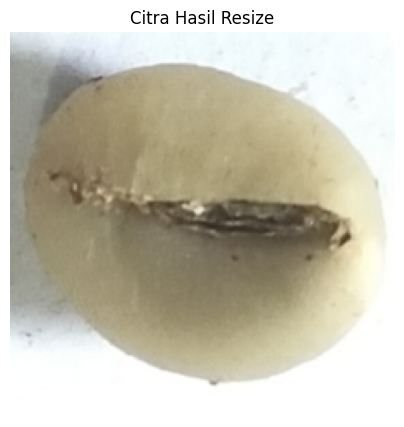

Red (R)        : 191.5285
Green (G)      : 187.0435
Blue (B)       : 168.5467
Contrast       : 15.2606
Energy         : 0.1389
Homogeneity    : 0.4950
Dissimilarity  : 2.0325
Correlation    : 0.9974
ASM            : 0.0193


In [7]:
# PENGGABUNGAN FITUR

fitur = [
    mean_r,
    mean_g,
    mean_b,
    contrast,
    energy,
    homogeneity,
    dissimilarity,
    correlation,
    asm
]

plt.figure(figsize=(5,5))
plt.imshow(cv2.cvtColor(img_resize, cv2.COLOR_BGR2RGB))
plt.title("Citra Hasil Resize")
plt.axis("off")
plt.show()

nama_fitur = [
    "Red (R)",
    "Green (G)",
    "Blue (B)",
    "Contrast",
    "Energy",
    "Homogeneity",
    "Dissimilarity",
    "Correlation",
    "ASM"
]

for nama, nilai in zip(nama_fitur, fitur):
    print(f"{nama:<15}: {nilai:.4f}")

TAHAP KLASIFIKASI SUPPORT VECTOR MACHINE

In [8]:
# MEMBENTUK DATASET FITUR

X = []
Y = []
image_paths = []

for label in ['baik', 'buruk']:

    path = os.path.join("../dataset", label)
    files = os.listdir(path)

    for file in files:

        img_path = os.path.join(path, file)
        img = cv2.imread(img_path)

        if img is None:
            continue

        # PREPROCESSING
        img_resize = cv2.resize(img, (224, 224))
        gray = cv2.cvtColor(img_resize, cv2.COLOR_BGR2GRAY)

        # RGB
        mean_r = np.mean(img_resize[:, :, 2])
        mean_g = np.mean(img_resize[:, :, 1])
        mean_b = np.mean(img_resize[:, :, 0])

        # GLCM
        glcm = graycomatrix(gray, [1], [0], 256, symmetric=True, normed=True)

        contrast = graycoprops(glcm, 'contrast')[0,0]
        energy = graycoprops(glcm, 'energy')[0,0]
        homogeneity = graycoprops(glcm, 'homogeneity')[0,0]
        dissimilarity = graycoprops(glcm, 'dissimilarity')[0,0]
        correlation = graycoprops(glcm, 'correlation')[0,0]
        asm = graycoprops(glcm, 'ASM')[0,0]

        fitur = [
            mean_r,
            mean_g,
            mean_b,
            contrast,
            energy,
            homogeneity,
            dissimilarity,
            correlation,
            asm
        ]

        X.append(fitur)
        image_paths.append(img_path)

        if label == 'baik':
            Y.append(1)
        else:
            Y.append(0)

# SPLIT DATA

X_train, X_test, Y_train, Y_test, train_paths, test_paths = train_test_split(
    X,
    Y,
    image_paths,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

print("SPLIT DATA")
print("Jumlah Data Training :", len(X_train))
print("Jumlah Data Testing  :", len(X_test))

SPLIT DATA
Jumlah Data Training : 240
Jumlah Data Testing  : 60


In [9]:
# NORMALISASI DATA

X_train_asli = X_train.copy()
X_test_asli = X_test.copy()

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("=== HASIL NORMALISASI DATA ===")
print("Data Training :", X_train.shape)
print("Data Testing  :", X_test.shape)

print("\n=== 10 DATA TRAINING PERTAMA SETELAH NORMALISASI ===\n")

for i in range(10):

    print(f"Data Training {i+1}")

    print(f"Red (R)         : {X_train[i][0]:.4f}")
    print(f"Green (G)       : {X_train[i][1]:.4f}")
    print(f"Blue (B)        : {X_train[i][2]:.4f}")
    print(f"Contrast        : {X_train[i][3]:.4f}")
    print(f"Energy          : {X_train[i][4]:.4f}")
    print(f"Homogeneity     : {X_train[i][5]:.4f}")
    print(f"Dissimilarity   : {X_train[i][6]:.4f}")
    print(f"Correlation     : {X_train[i][7]:.4f}")
    print(f"ASM             : {X_train[i][8]:.4f}")

    print("-"*50)

=== HASIL NORMALISASI DATA ===
Data Training : (240, 9)
Data Testing  : (60, 9)

=== 10 DATA TRAINING PERTAMA SETELAH NORMALISASI ===

Data Training 1
Red (R)         : 1.3006
Green (G)       : 1.3942
Blue (B)        : 1.3581
Contrast        : -1.0002
Energy          : 0.1176
Homogeneity     : 1.3974
Dissimilarity   : -1.2574
Correlation     : 0.8355
ASM             : -0.1806
--------------------------------------------------
Data Training 2
Red (R)         : -1.2070
Green (G)       : -1.1594
Blue (B)        : -1.0799
Contrast        : 0.3998
Energy          : -0.5449
Homogeneity     : -0.4395
Dissimilarity   : 0.3348
Correlation     : -0.2383
ASM             : -0.4447
--------------------------------------------------
Data Training 3
Red (R)         : 1.0241
Green (G)       : 0.9385
Blue (B)        : 0.5205
Contrast        : -1.0250
Energy          : -0.2938
Homogeneity     : 0.8068
Dissimilarity   : -1.1780
Correlation     : 1.0480
ASM             : -0.3697
--------------------------

Model SVM berhasil dilatih.


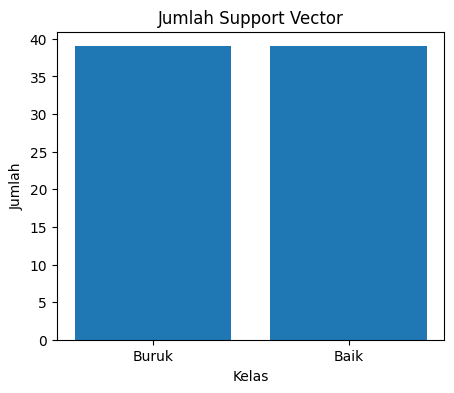

In [10]:
# TRAINING SVM

model = SVC(
    kernel='rbf',
    C=5,
    gamma=0.1
)

model.fit(X_train, Y_train)

kelas = ["Buruk", "Baik"]
jumlah_sv = model.n_support_

print("Model SVM berhasil dilatih.")

plt.figure(figsize=(5,4))
plt.bar(kelas, jumlah_sv)

plt.title("Jumlah Support Vector")
plt.xlabel("Kelas")
plt.ylabel("Jumlah")

plt.show()

=== HASIL KLASIFIKASI DATA TESTING ===
Jumlah Data Testing : 60
Jumlah Hasil Prediksi : 60

===== DATA TESTING 1 =====


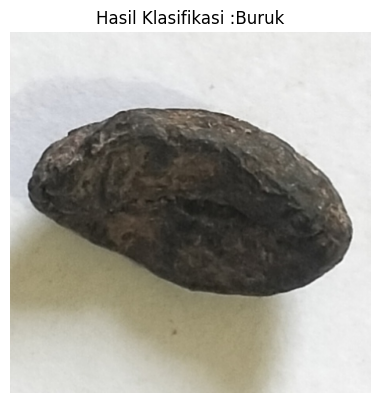

Prediksi : Buruk

===== DATA TESTING 2 =====


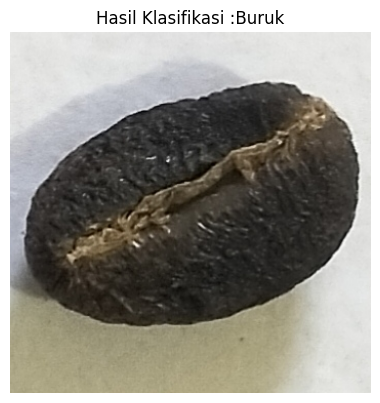

Prediksi : Buruk

===== DATA TESTING 3 =====


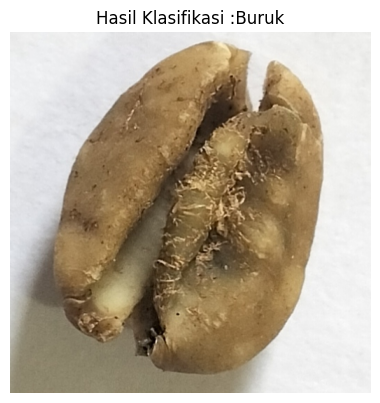

Prediksi : Buruk

===== DATA TESTING 4 =====


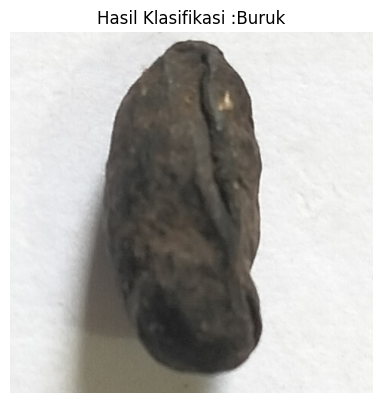

Prediksi : Buruk

===== DATA TESTING 5 =====


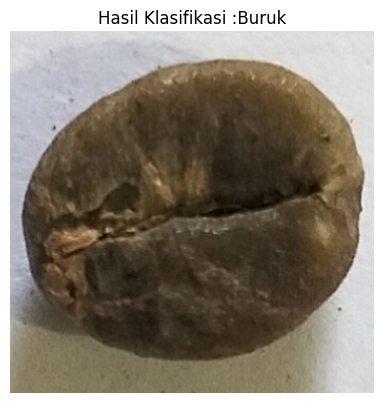

Prediksi : Buruk

===== DATA TESTING 6 =====


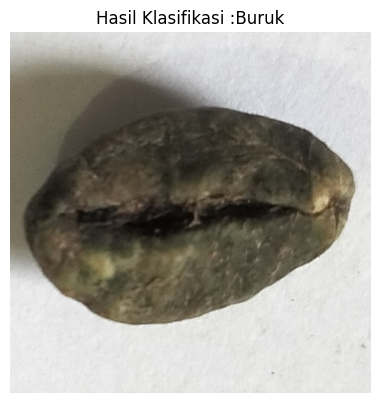

Prediksi : Buruk

===== DATA TESTING 7 =====


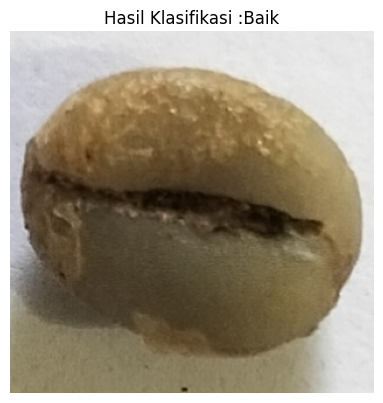

Prediksi : Baik

===== DATA TESTING 8 =====


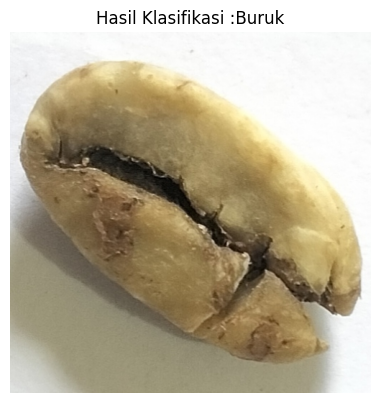

Prediksi : Buruk

===== DATA TESTING 9 =====


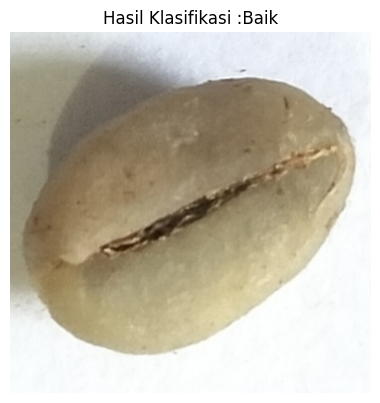

Prediksi : Baik

===== DATA TESTING 10 =====


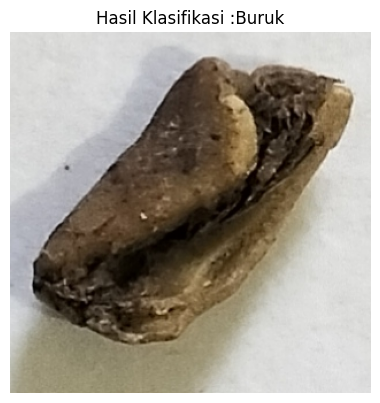

Prediksi : Buruk


In [11]:
# KLASIFIKASI DATA TESTING

Y_pred = model.predict(X_test)

print("=== HASIL KLASIFIKASI DATA TESTING ===")
print(f"Jumlah Data Testing : {len(Y_test)}")
print(f"Jumlah Hasil Prediksi : {len(Y_pred)}")

for i in range(10):

    # Ambil gambar asli
    img = cv2.imread(test_paths[i])
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    prediksi = "Baik" if Y_pred[i] == 1 else "Buruk"

    print(f"\n===== DATA TESTING {i+1} =====")

    plt.figure(figsize=(8,4))

    # Input Citra

    # Hasil Klasifikasi
    plt.subplot(1,2,2)
    plt.imshow(img_rgb)
    plt.title(f"Hasil Klasifikasi :{prediksi}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Prediksi :", prediksi)

========== HASIL EVALUASI MODEL ==========



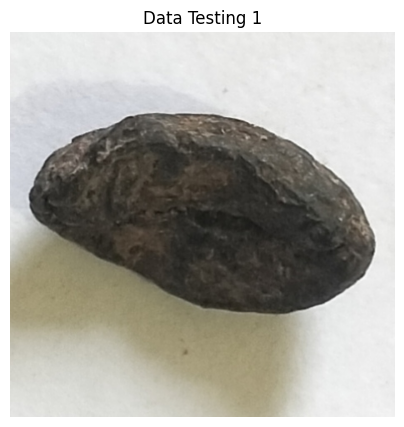

========== DATA TESTING 1 ==========
Label Asli     : Buruk
Hasil Prediksi : Buruk
--------------------------------------------------


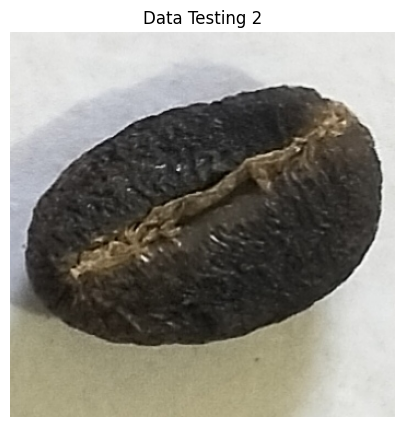

========== DATA TESTING 2 ==========
Label Asli     : Buruk
Hasil Prediksi : Buruk
--------------------------------------------------


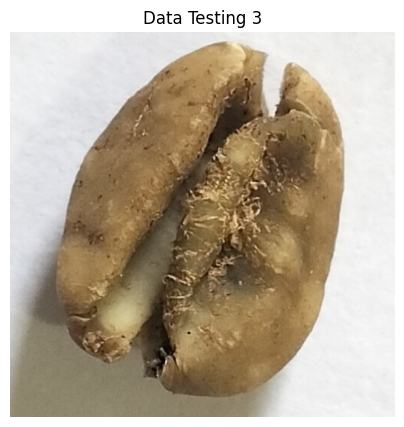

========== DATA TESTING 3 ==========
Label Asli     : Buruk
Hasil Prediksi : Buruk
--------------------------------------------------


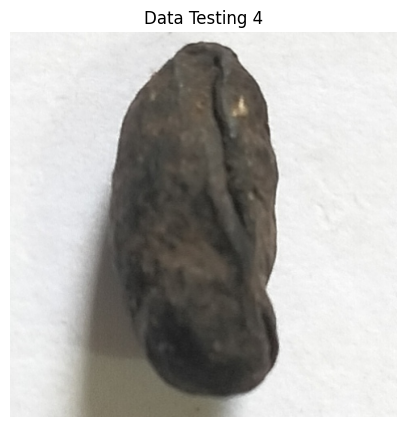

========== DATA TESTING 4 ==========
Label Asli     : Buruk
Hasil Prediksi : Buruk
--------------------------------------------------


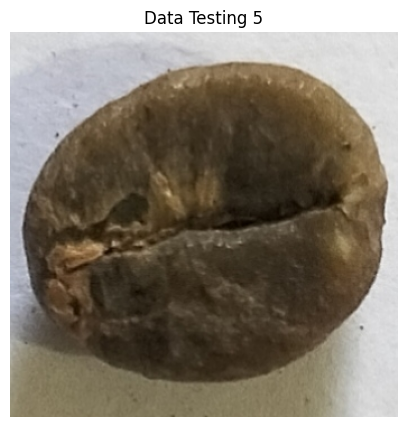

========== DATA TESTING 5 ==========
Label Asli     : Buruk
Hasil Prediksi : Buruk
--------------------------------------------------


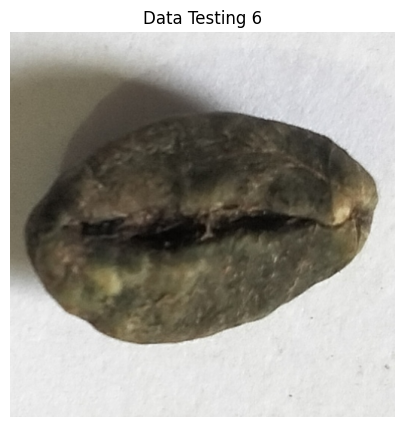

========== DATA TESTING 6 ==========
Label Asli     : Buruk
Hasil Prediksi : Buruk
--------------------------------------------------


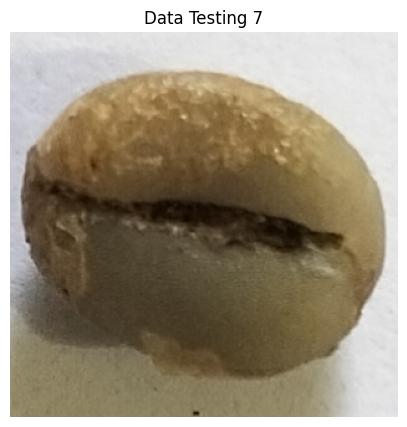

========== DATA TESTING 7 ==========
Label Asli     : Baik
Hasil Prediksi : Baik
--------------------------------------------------


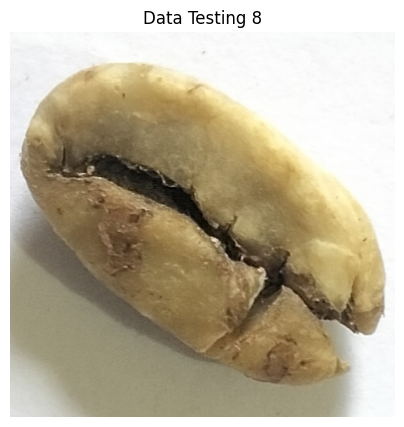

========== DATA TESTING 8 ==========
Label Asli     : Buruk
Hasil Prediksi : Buruk
--------------------------------------------------


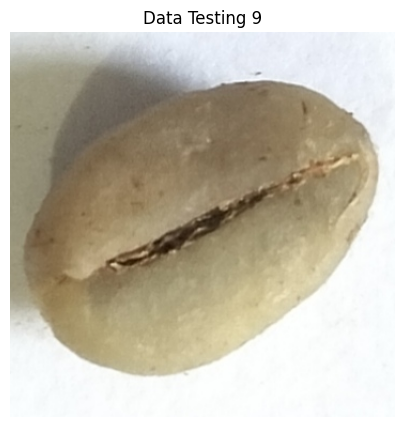

========== DATA TESTING 9 ==========
Label Asli     : Baik
Hasil Prediksi : Baik
--------------------------------------------------


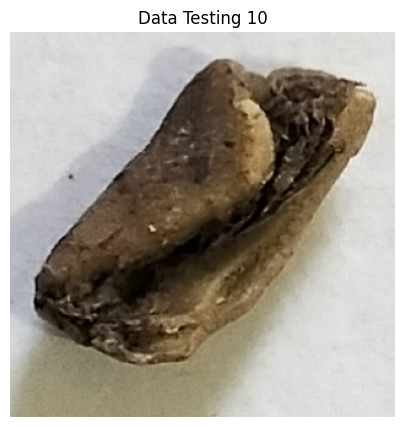

========== DATA TESTING 10 ==========
Label Asli     : Buruk
Hasil Prediksi : Buruk
--------------------------------------------------


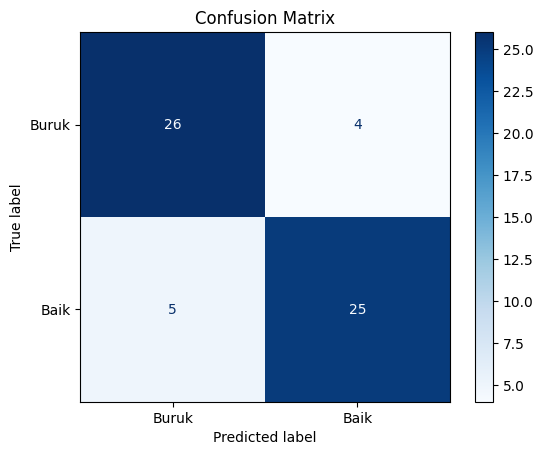


========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

       Buruk       0.84      0.87      0.85        30
        Baik       0.86      0.83      0.85        30

    accuracy                           0.85        60
   macro avg       0.85      0.85      0.85        60
weighted avg       0.85      0.85      0.85        60

========== HASIL EVALUASI ==========

Accuracy  : 85.00%
Precision : 86.21%
Recall    : 83.33%
F1-Score  : 84.75%


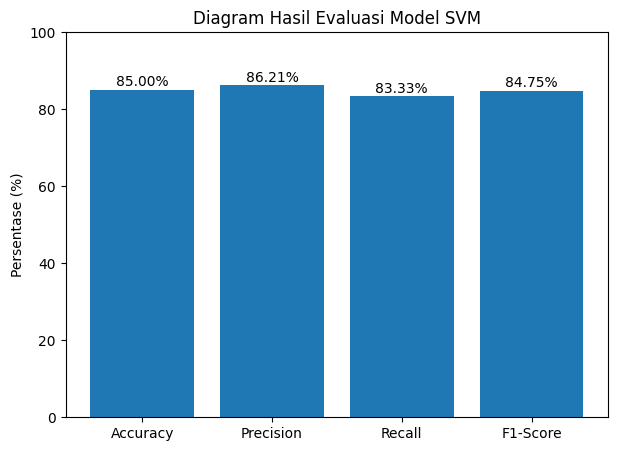

In [12]:
# ===============================
# EVALUASI MODEL
# ===============================

accuracy = accuracy_score(Y_test, Y_pred)
precision = precision_score(Y_test, Y_pred)
recall = recall_score(Y_test, Y_pred)
f1 = f1_score(Y_test, Y_pred)

cm = confusion_matrix(Y_test, Y_pred)

print("========== HASIL EVALUASI MODEL ==========\n")

# ===============================
# MENAMPILKAN 10 DATA TESTING
# ===============================

for i in range(10):

    img = cv2.imread(test_paths[i])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(5,5))
    plt.imshow(img)
    plt.title(f"Data Testing {i+1}")
    plt.axis("off")
    plt.show()

    print(f"========== DATA TESTING {i+1} ==========")
    print("Label Asli     :", "Baik" if Y_test[i] == 1 else "Buruk")
    print("Hasil Prediksi :", "Baik" if Y_pred[i] == 1 else "Buruk")
    print("-"*50)


# ===============================
# CONFUSION MATRIX
# ===============================

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Buruk", "Baik"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()


# ===============================
# CLASSIFICATION REPORT
# ===============================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(classification_report(
    Y_test,
    Y_pred,
    target_names=["Buruk", "Baik"]
))


# ===============================
# HASIL EVALUASI
# ===============================

print("========== HASIL EVALUASI ==========\n")

print(f"Accuracy  : {accuracy*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1-Score  : {f1*100:.2f}%")


# ===============================
# DIAGRAM HASIL EVALUASI
# ===============================

metrik = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

nilai = [
    accuracy*100,
    precision*100,
    recall*100,
    f1*100
]

plt.figure(figsize=(7,5))

bars = plt.bar(metrik, nilai)

plt.ylim(0,100)

plt.ylabel("Persentase (%)")
plt.title("Diagram Hasil Evaluasi Model SVM")

for bar in bars:

    tinggi = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        tinggi+1,
        f"{tinggi:.2f}%",
        ha='center'
    )

plt.show()